#### Вырезка прямоугольной области с оригинальным текстом и заливка фоном

Изображение сохранено: RedrawFr/output.bmp


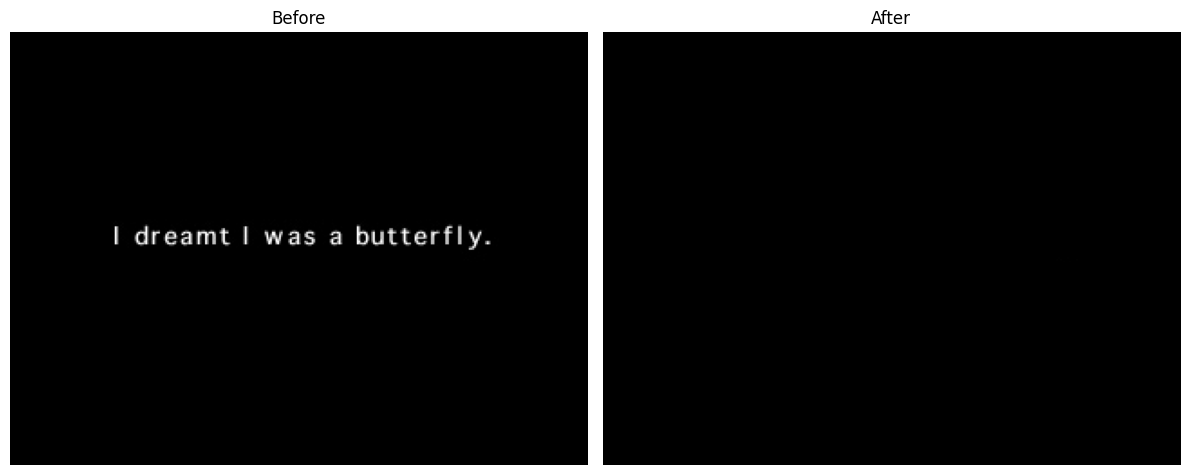

In [20]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display
from sympy.matrices.expressions.blockmatrix import bc_unpack


def remove_rectangular_area(image_path, output_path, x, y, w, h):
    """
    Удаляет прямоугольную область на изображении, заливая её указанным цветом.
    
    Параметры:
    - image_path: путь к исходному изображению
    - output_path: путь для сохранения результата
    - x, y: координаты верхнего левого угла прямоугольника
    - w, h: ширина и высота прямоугольника
    - fill_color: цвет заливки (по умолчанию белый)
    """
    # Загрузка изображения
    img = cv2.imread(image_path)
    
    if img is None:
        print("Ошибка: не удалось загрузить изображение")
        return False
    
    pixel = img[0, 0]  # в OpenCV сначала y, потом x
    # В OpenCV цвета идут в порядке BGR (Blue, Green, Red)
    blue, green, red = pixel
    fill_color = (blue, green, red)
    
    # Проверка границ прямоугольника
    height, width = img.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)
    
    # Заливка прямоугольной области
    img[y1:y2, x1:x2] = fill_color
    
    # Сохранение результата
    cv2.imwrite(output_path, img)
    print(f"Изображение сохранено: {output_path}")
    
    # Открытие изображений
    img_start = Image.open(image_path)
    img_finish = Image.open(output_path)
    
    # Создание двух подграфиков горизонтально
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # Отображение первого изображения
    ax1.imshow(img_start)
    ax1.set_title('Before')
    ax1.axis('off')
    
    # Отображение второго изображения
    ax2.imshow(img_finish)
    ax2.set_title('After')
    ax2.axis('off')
    
    plt.tight_layout()
    plt.show()
    



# Параметры
input_image = "RedrawFr/MV1C.STR[0][0034].bmp"      # путь к исходному изображению
output_image = "RedrawFr/output.bmp"    # путь для сохранения

# Координаты и размеры удаляемой области
x, y = 52, 103    # координаты верхнего левого угла
width = 224       # ширина области
height = 22      # высота области


remove_rectangular_area(input_image, output_image, x, y, width, height)
   

#### Вставка в центр переведенный текст

Изображение сохранено: RedrawFr/output_1.bmp


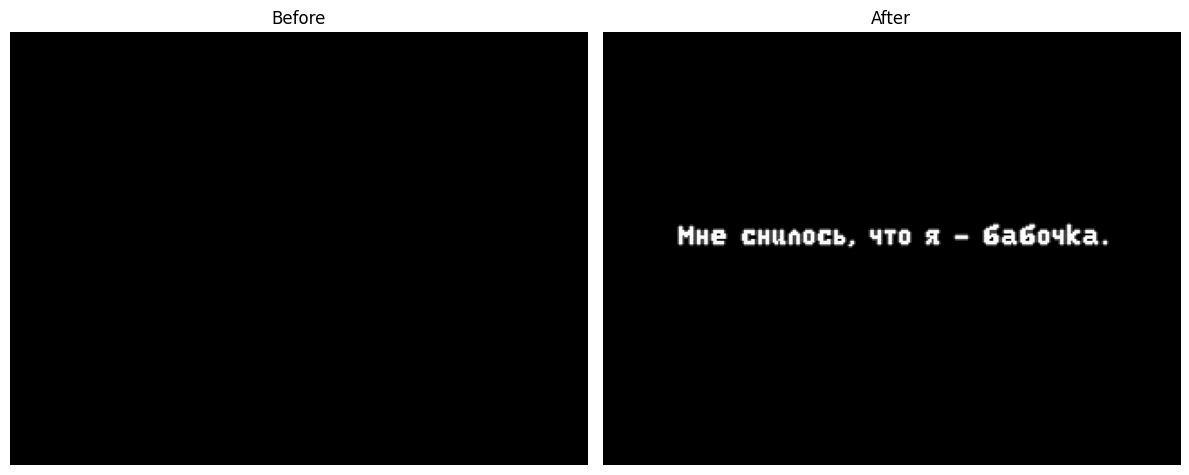

In [17]:
import cv2
import numpy as np

def paste_opencv(b_path, o_path, position=(0, 0)):
    """
    Вставка с помощью OpenCV
    """
    # Загрузка изображений
    base = cv2.imread(b_path)
    overlay = cv2.imread(o_path)
    
    x, y = position
    # Вставка
    base[y:y+overlay.shape[0], x:x+overlay.shape[1]] = overlay
    
    return base

base_path = 'RedrawFr/output.bmp'
overlay_path = 'RedrawFr/phrase_1.png'
output_path = 'RedrawFr/output_1.bmp'

# Использование
result = paste_opencv(base_path, overlay_path, position=(41, 106))
cv2.imwrite(output_path, result)
print(f"Изображение сохранено: {output_path}")

# Открытие изображений
img_start = Image.open(base_path)
img_finish = Image.open(output_path)

# Создание двух подграфиков горизонтально
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Отображение первого изображения
ax1.imshow(img_start)
ax1.set_title('Before')
ax1.axis('off')

# Отображение второго изображения
ax2.imshow(img_finish)
ax2.set_title('After')
ax2.axis('off')

plt.tight_layout()
plt.show()

#### Весь код для изменения одного кадра 1 фразы

Изображение сохранено: RedrawFr/output.bmp


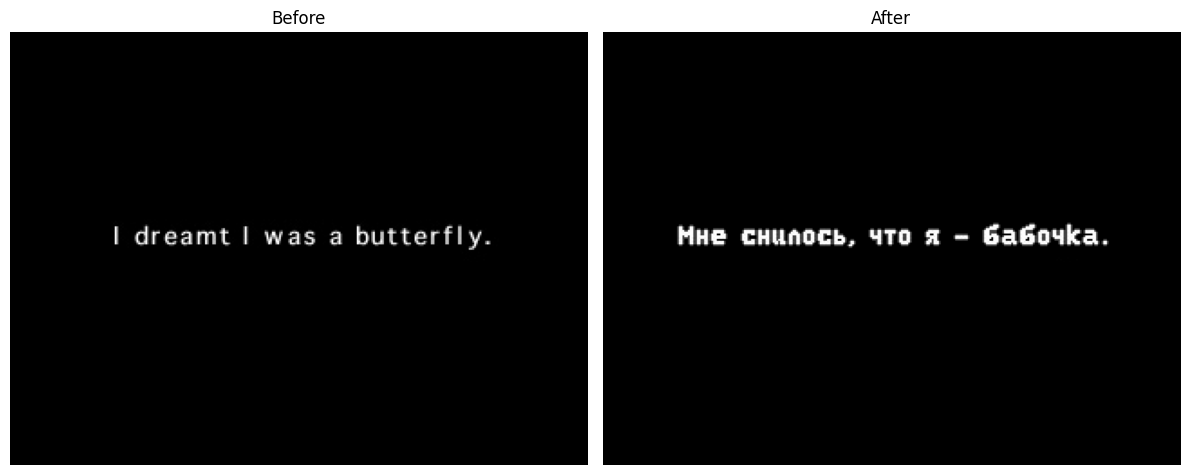

In [22]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def remove_rectangular_area(image_path, output_path, x, y, w, h):
    """
    Удаляет прямоугольную область на изображении, заливая её указанным цветом.
    """
    
    # Загрузка изображения
    img = cv2.imread(image_path)
    
    if img is None:
        print("Ошибка: не удалось загрузить изображение")
        return False
    
    # Проверка границ прямоугольника
    height, width = img.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)
    
    pixel = img[0, 0]  # В OpenCV цвета идут в порядке BGR (Blue, Green, Red)
    
    # Заливка прямоугольной области
    img[y1:y2, x1:x2] = pixel
    
    return img
    
    
def paste_opencv(b_img, o_path, position=(0, 0)):
    """
    Вставка с помощью OpenCV
    """
    # Загрузка изображений
    overlay = cv2.imread(o_path)
    
    x, y = position
    # Вставка
    b_img[y:y+overlay.shape[0], x:x+overlay.shape[1]] = overlay
    
    return b_img

    
# Параметры
input_image = "RedrawFr/MV1C.STR[0][0034].bmp"      # путь к исходному изображению
overlay_image = 'RedrawFr/phrase_1.png'              # путь к переведенной надписи
output_image = "RedrawFr/output.bmp"                # путь для сохранения

# Координаты и размеры удаляемой области
x, y = 52, 103    # координаты верхнего левого угла
width = 224       # ширина области
height = 22      # высота области

base_img = remove_rectangular_area(input_image, output_image, x, y, width, height)

result = paste_opencv(base_img, overlay_image, position=(41, 106))
cv2.imwrite(output_image, result)
print(f"Изображение сохранено: {output_image}")


# Открытие изображений
img_start = Image.open(input_image)
img_finish = Image.open(output_image)

# Создание двух подграфиков горизонтально
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Отображение первого изображения
ax1.imshow(img_start)
ax1.set_title('Before')
ax1.axis('off')

# Отображение второго изображения
ax2.imshow(img_finish)
ax2.set_title('After')
ax2.axis('off')

plt.tight_layout()
plt.show()